**Importing all the libraries**

In [65]:

import pandas as pd
import numpy as np
import re
import string

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix,precision_score,recall_score,f1_score


# **1. Loading and preprocessing**


**Loading the dataset**

In [66]:
df=pd.read_csv('/content/nlp_dataset.csv')
df

,Comment,Emotion
0,i seriously hate one subject to death but now ...,fear
1,im so full of life i feel appalled,anger
2,i sit here to write i start to dig out my feel...,fear
3,ive been really angry with r and i feel like a...,joy
4,i feel suspicious if there is no one outside l...,fear
...,...,...
5932,i begun to feel distressed for you,fear
5933,i left feeling annoyed and angry thinking that...,anger
5934,i were to ever get married i d have everything...,joy
5935,i feel reluctant in applying there because i w...,fear


In [67]:
df.shape

(5937, 2)

In [68]:
df.columns

Index(['Comment', 'Emotion'], dtype='object')

In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5937 entries, 0 to 5936
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Comment  5937 non-null   object
 1   Emotion  5937 non-null   object
dtypes: object(2)
memory usage: 92.9+ KB


In [70]:
df.isnull().sum()

,0
Comment,0
Emotion,0


In [71]:
df["Emotion"].value_counts()

,count
Emotion,
anger,2000
joy,2000
fear,1937


In [72]:
df.duplicated().sum()

np.int64(0)

In [73]:
df["Emotion"].unique()

array(['fear', 'anger', 'joy'], dtype=object)

In [74]:

df = df.dropna(subset=["Comment", "Emotion"]).copy()
df = df.drop_duplicates().copy()
df.shape


(5937, 2)

**Text Cleaning and Lowercase**

In [75]:
def clean_text(text):
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', '', text)

    # Remove punctuation, numbers, and special characters
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text.strip()

df["Cleaned_Text"] = df["Comment"].apply(clean_text)
df


,Comment,Emotion,Cleaned_Text
0,i seriously hate one subject to death but now ...,fear,i seriously hate one subject to death but now ...
1,im so full of life i feel appalled,anger,im so full of life i feel appalled
2,i sit here to write i start to dig out my feel...,fear,i sit here to write i start to dig out my feel...
3,ive been really angry with r and i feel like a...,joy,ive been really angry with r and i feel like a...
4,i feel suspicious if there is no one outside l...,fear,i feel suspicious if there is no one outside l...
...,...,...,...
5932,i begun to feel distressed for you,fear,i begun to feel distressed for you
5933,i left feeling annoyed and angry thinking that...,anger,i left feeling annoyed and angry thinking that...
5934,i were to ever get married i d have everything...,joy,i were to ever get married i d have everything...
5935,i feel reluctant in applying there because i w...,fear,i feel reluctant in applying there because i w...


**Remove punctuation, tokenize text, and remove stopwords**

In [76]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

stop_words = set(stopwords.words("english"))
stop_words = stop_words-{"not", "no", "nor", "never"}

def preprocess_text(text):
    words = word_tokenize(text)
    words = [word for word in words if word not in stop_words]
    return " ".join(words)

df["Comment"] = df["Comment"].apply(preprocess_text)
df.head()

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,Comment,Emotion,Cleaned_Text
0,seriously hate one subject death feel reluctan...,fear,i seriously hate one subject to death but now ...
1,im full life feel appalled,anger,im so full of life i feel appalled
2,sit write start dig feelings think afraid acce...,fear,i sit here to write i start to dig out my feel...
3,ive really angry r feel like idiot trusting fi...,joy,ive been really angry with r and i feel like a...
4,feel suspicious no one outside like rapture ha...,fear,i feel suspicious if there is no one outside l...


**Explain the preprocessing steps.**

---
### Loading and Preprocessing

The dataset was loaded using Pandas and inspected to understand its structure, columns, and missing values. The `Comment` column was used as the input text, and the `Emotion` column was used as the target variable.

The following preprocessing techniques were applied:

1. **Missing value and duplicate handling:** Rows with missing comments or emotion labels were removed, and exact duplicate rows were eliminated to reduce redundant records.

2. **Text cleaning:** Text was converted to lowercase, URLs were removed, punctuation and numbers were replaced with spaces, and extra whitespace was eliminated. This helped standardize the text and reduce irrelevant variation.

3. **Tokenization:** Each cleaned comment was split into individual word tokens using NLTK's `word_tokenize()` function. This prepared the text for further processing.

4. **Stopword removal:** Common English stopwords were removed using NLTK. Negation words such as "not", "no", "nor", and "never" were preserved because they can change the meaning of a comment.

5. **Final text preparation:** The remaining tokens were joined into strings and stored in a new `Processed_Text` column for feature extraction.

These preprocessing steps can reduce noise and help machine learning models identify informative words. However, excessive cleaning may remove useful emotional cues or context. Therefore, preprocessing choices should ultimately be evaluated by comparing model performance using metrics such as accuracy and F1-score.


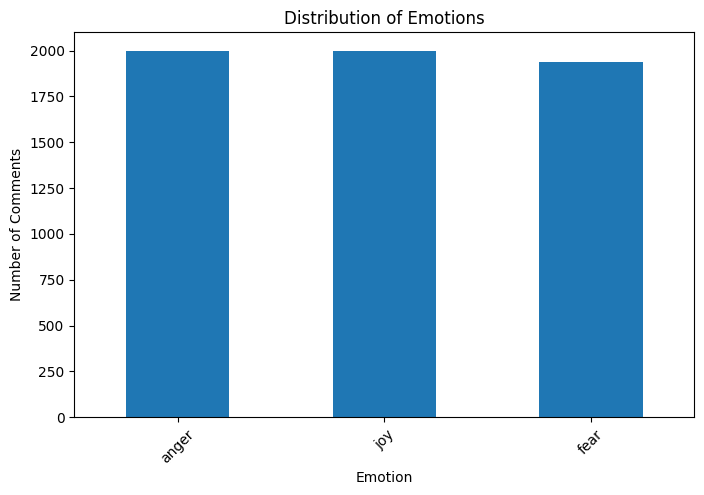

In [77]:

df["Emotion"].value_counts().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Distribution of Emotions")
plt.xlabel("Emotion")
plt.ylabel("Number of Comments")
plt.xticks(rotation=45)
plt.show()


# **2. Feature extraction**
- Use CountVectorizer or TfidfVectorizer.
- Convert text into numerical features for the models.

# **Separating input and output**

In [78]:

X = df["Comment"]
y = df["Emotion"]

In [79]:
X_train, X_test, y_train, y_test=train_test_split(X, y,test_size=0.30,random_state=42,stratify=y)
print(len(X_train))
print(len(X_test))

4155
1782


In [80]:
# Create the TF-IDF vectorizer
tfidf = TfidfVectorizer(max_features=5000)

# Convert text into numerical features
X_train_tfidf=tfidf.fit_transform(X_train)
X_test_tfidf=tfidf.transform(X_test)
print(X_train_tfidf.shape)
print(X_test_tfidf.shape)


(4155, 5000)
(1782, 5000)


TfidfVectorizer() creates the vectorizer.



max_features=5000 limits the vocabulary to at most 5,000 features.



fit_transform() learns the vocabulary and IDF weights from the text, then transforms the text into a sparse numerical matrix.



X_tfidf contains the numerical representation of your comments.



y contains the emotion labels that the models will learn to predict.

### Feature Extraction Using TF-IDF

TF-IDF (Term Frequency–Inverse Document Frequency) was used to convert the preprocessed text into numerical features. Machine learning algorithms such as Naive Bayes and Support Vector Machine cannot directly process raw text, so numerical representation is required.

TF-IDF assigns weights to words based on their frequency within a comment and their distribution across the collection of comments. Words that occur frequently in a particular comment but less frequently across the dataset may receive higher weights, while very common words receive lower weights.

The `TfidfVectorizer` from Scikit-learn was used with `max_features=5000` to limit the vocabulary to at most 5,000 features. The resulting sparse matrix represents each comment numerically and can be used as input for the classification models.

TF-IDF helps emphasize potentially informative words and provides a suitable feature representation for text classification. Its effectiveness will be assessed by comparing the performance of the Naive Bayes and SVM models using appropriate evaluation metrics.

**Model Development**

● Train the following machine learning models

a)Naive Bayes

b)Support Vector Machine

# **Naive Bayes Model**

In [81]:
nb=MultinomialNB()
nb.fit(X_train_tfidf, y_train)
nb_pred=nb.predict(X_test_tfidf)
nb_accuracy=accuracy_score(y_test,nb_pred)
nb_precision=precision_score(y_test,nb_pred, average="weighted", zero_division=0)
nb_recall=recall_score(y_test,nb_pred, average="weighted", zero_division=0)
nb_f1=f1_score(y_test, nb_pred,average="weighted", zero_division=0)

print("Naive Bayes Accuracy:", nb_accuracy)
print("Naive Bayes Precision:", nb_precision)
print("Naive Bayes Recall:", nb_recall)
print("Naive Bayes F1 Score:", nb_f1)

Naive Bayes Accuracy: 0.8995510662177328
Naive Bayes Precision: 0.9009060399770963
Naive Bayes Recall: 0.8995510662177328
Naive Bayes F1 Score: 0.8996036208759867


# **SVM Model**

In [82]:
svm=LinearSVC(random_state=42)
svm.fit(X_train_tfidf, y_train)
svm_pred=svm.predict(X_test_tfidf)
svm_accuracy=accuracy_score(y_test,svm_pred)
svm_precision=precision_score(y_test,svm_pred, average="weighted", zero_division=0)
svm_recall=recall_score(y_test,svm_pred, average="weighted", zero_division=0)
svm_f1=f1_score(y_test,svm_pred, average="weighted", zero_division=0)
print("SVM Accuracy:", svm_accuracy)
print("SVM Precision:", svm_precision)
print("SVM Recall:", svm_recall)
print("SVM F1 Score:", svm_f1)


SVM Accuracy: 0.936026936026936
SVM Precision: 0.9361155430782546
SVM Recall: 0.936026936026936
SVM F1 Score: 0.9360442860426809


# **Model Comparison**

---
Evaluate the model using appropriate metrics (e.g., accuracy, F1-score). Provide a brief
explanation of the chosen model and its suitability for emotion classification.



In [83]:
results = pd.DataFrame({
    "Model": ["Naive Bayes", "SVM"],
    "Accuracy": [nb_accuracy, svm_accuracy],
    "Precision": [nb_precision, svm_precision],
    "Recall": [nb_recall, svm_recall],
    "F1-score": [nb_f1, svm_f1]
})

print(results.round(4))

         Model  Accuracy  Precision  Recall  F1-score
0  Naive Bayes    0.8996     0.9009  0.8996    0.8996
1          SVM    0.9360     0.9361  0.9360    0.9360


**Naive Bayes**: Achieved 89.96% accuracy and 89.96% weighted F1-score. It is efficient and provides a strong baseline for text classification.



**SVM**: Achieved 93.60% accuracy and 93.60% weighted F1-score. Its strong performance makes it a suitable choice for classifying emotions from TF-IDF text features.



**Performance difference**: SVM achieved an accuracy improvement of 3.64 percentage points over Naive Bayes.

**Classification Report**

In [84]:
#classification report
from sklearn.metrics import classification_report
print("NAIVE BAYES REPORT")
print(classification_report(y_test, nb_pred, zero_division=0))
print("SVM REPORT")
print(classification_report(y_test, svm_pred, zero_division=0))


NAIVE BAYES REPORT
              precision    recall  f1-score   support

       anger       0.88      0.92      0.90       600
        fear       0.89      0.91      0.90       582
         joy       0.94      0.87      0.90       600

    accuracy                           0.90      1782
   macro avg       0.90      0.90      0.90      1782
weighted avg       0.90      0.90      0.90      1782

SVM REPORT
              precision    recall  f1-score   support

       anger       0.94      0.93      0.93       600
        fear       0.92      0.94      0.93       582
         joy       0.95      0.94      0.94       600

    accuracy                           0.94      1782
   macro avg       0.94      0.94      0.94      1782
weighted avg       0.94      0.94      0.94      1782



# **Predicting**

In [85]:
#new_comment=["I feel grateful for all the wonderful people in my life, and today I am genuinely happy."]
# new_comment=["I am afraid of walking alone in the dark because I feel something bad might happen."]
new_comment=["I am extremely angry because they ignored my feelings and treated me unfairly."]
cleaned_comment=[preprocess_text(clean_text(new_comment[0]))]
comment_tfidf=tfidf.transform(cleaned_comment)
prediction=svm.predict(comment_tfidf)
print("Comment:", new_comment[0])
print("Predicted Emotion:", prediction[0])

Comment: I am extremely angry because they ignored my feelings and treated me unfairly.
Predicted Emotion: anger
